# CLFG snowpack stratigraphy · WY2026

One SNOWPACK simulation at CLFG on Mendenhall Glacier uses 100 m TopoPyScale forcing. The first figure shows how snow density, liquid water content, temperature, and grain type vary with time and height through the water year. The second shows the native model layers for density and temperature at local noon on the snow-depth observation date. The field record gives an approximate depth and has no recorded time of day, so noon is a representative modeled snapshot.

The notebook uses the existing hourly `.pro` output. Set `CLFG_MODEL_SITE` to use an alternate site directory containing that run.

The figures follow the PPSA seasonal snow-site figures, with NiViz-style color scales and ground-aligned snow layers.

In [1]:
from pathlib import Path
import os
import sys
from zoneinfo import ZoneInfo

import matplotlib as mpl
from matplotlib.collections import PolyCollection
import matplotlib.dates as mdates
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import MultipleLocator
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd()
root = next(p for p in (cwd, *cwd.parents, cwd / "jif_snow_modeling")
            if (p / "sites/clfg/site_info.txt").is_file())
sys.path.insert(0, str(root / "sites/radar_sites/scripts"))
from prepare_radar_site_forcing import MODEL_ROOT, read_smet
plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({"font.family": "DejaVu Sans", "pdf.fonttype": 42})
info = dict(line.split(": ", 1) for line in (root / "sites/clfg/site_info.txt").read_text().splitlines())
observed_depth = float(info["Snow depth"].split()[1])
timezone = ZoneInfo("America/Juneau")
observation_day = pd.Timestamp(info["Observation date"], tz=timezone)
snapshot = observation_day + pd.Timedelta(hours=12)

site_dir = Path(os.environ.get("CLFG_MODEL_SITE", MODEL_ROOT / "clfg")).expanduser()
run = site_dir / "output/topopyscale_100m_clfg_WY2026_heatflux_soiltemp_zero"
run_label = "100 m TopoPyScale forcing"
expected_utc = pd.date_range("2025-10-01", "2026-10-01", freq="h", inclusive="left", tz="UTC")


## Read the hourly layer output

SNOWPACK writes layer-top heights above the model base in centimeters (`0501`), layer density in kg/m³ (`0502`), layer temperature in °C (`0503`), liquid water content by volume (`0506`), and Swiss F1F2F3 grain codes (`0513`). The simulation has no modeled soil layers. The single zero-height record marks a snow-free hour. Timestamps in the output are UTC and are converted to Juneau time for display and for selecting the noon snapshot.

In [2]:
layer_fields = {
    "height": b"0501,", "density": b"0502,", "temperature": b"0503,",
    "liquid_water": b"0506,", "grain_type": b"0513,",
}


def read_profiles(path):
    records = []
    with path.open("rb") as stream:
        for line in stream:
            if line.strip() == b"[DATA]":
                break
        for line in stream:
            record = line[:5]
            if record == b"0500,":
                timestamp = line[5:].strip().decode()
                fields = {}
                records.append((timestamp, fields))
            elif record in layer_fields.values():
                _, count, payload = line.split(b",", 2)
                values = np.fromstring(payload.decode(), sep=",")
                if values.size != int(count):
                    raise ValueError(f"Invalid {record!r} element count at {timestamp}")
                fields[record] = values

    times = pd.to_datetime([time for time, _ in records], format="%d.%m.%Y %H:%M:%S", utc=True)
    layers = []
    for (timestamp, fields) in records:
        tops = fields[layer_fields["height"]]
        if tops.size == 1 and tops[0] == 0:
            layers.append({name: np.empty(0) for name in layer_fields})
            continue
        profile = {name: fields[code] for name, code in layer_fields.items()}
        if profile["grain_type"].size == tops.size + 1:
            # SNOWPACK can append a surface-hoar flag without a corresponding layer.
            profile["grain_type"] = profile["grain_type"][:-1]
        if (any(v.size != tops.size or not np.isfinite(v).all() for v in profile.values())
                or (np.diff(tops) < 0).any() or (tops <= 0).any()
                or (profile["density"] <= 0).any()
                or (profile["liquid_water"] < 0).any()
                or (profile["grain_type"] % 1 != 0).any()):
            raise ValueError(f"Invalid snow layers at {timestamp}")
        profile["height"] = tops / 100
        layers.append(profile)
    return times, layers


times_utc, profiles = read_profiles(run.with_suffix(".pro"))
if not times_utc.equals(expected_utc):
    raise ValueError("Expected one SNOWPACK profile per hour for all of WY2026")
times = times_utc.tz_convert(timezone)
modeled_depth = np.array([p["height"][-1] if p["height"].size else 0 for p in profiles])

header, hourly = read_smet(run.with_suffix(".smet"), ["timestamp", "HS_mod"])
height_index = header["fields"].split().index("HS_mod")
height_scale = float(header["units_multiplier"].split()[height_index])
if not hourly.index.tz_localize("UTC").equals(times_utc):
    raise ValueError("Profile and time-series timestamps differ")
np.testing.assert_allclose(modeled_depth, hourly.HS_mod * height_scale, rtol=0, atol=0.00011)

snapshot_profile = profiles[times.get_loc(snapshot)]
tops = snapshot_profile["height"]
density = snapshot_profile["density"]
temperature = snapshot_profile["temperature"]
if not tops.size:
    raise ValueError(f"The snow column is empty at {snapshot}")
print(f"{snapshot:%B %d, %Y at %I:%M %p %Z} · {tops.size} simulated layers")
print(f"Modeled depth {tops[-1]:.2f} m · Approximate field depth {observed_depth:g} m")


May 25, 2026 at 12:00 PM AKDT · 458 simulated layers
Modeled depth 2.16 m · Approximate field depth 2 m


## Seasonal snowpack stratigraphy

The four panels show native layer thickness at three-hour intervals, matching the seasonal-site figures. Empty space above the simulated snow surface is blank. The dashed line marks the May 25 snapshot. The liquid-water scale saturates at 4 vol. %, and the grain panel groups Swiss codes by primary type, with melt–freeze crust (772) shown separately.

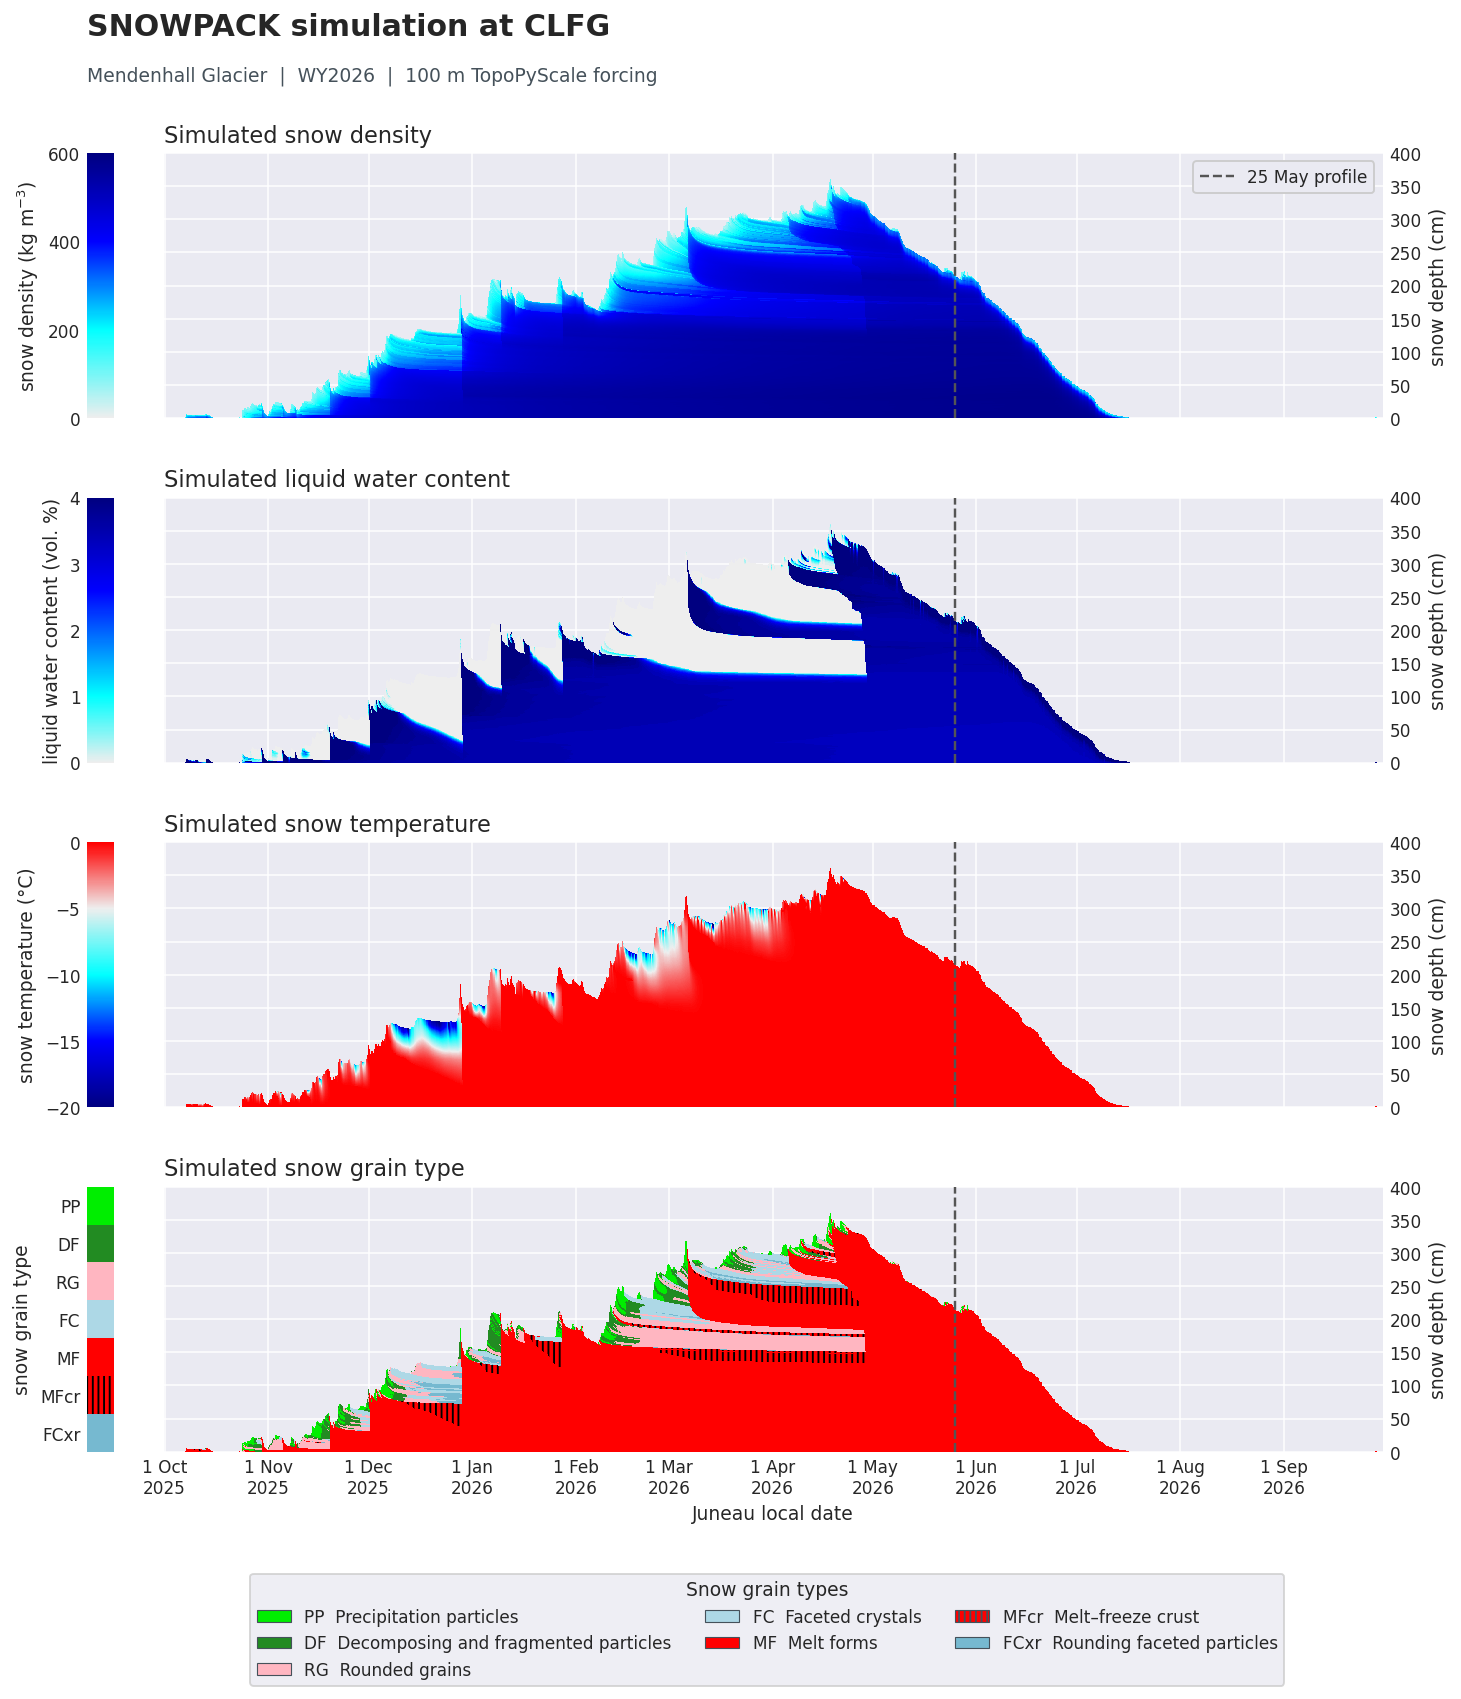

In [3]:
density_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "snow_density", ["#eeeeee", "#00ffff", "#0000ff", "#000080"],
)
temperature_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "snow_temperature", ["#000080", "#0000ff", "#00ffff", "#eeeeee", "#ff0000"],
)
density_norm = mpl.colors.Normalize(0, 600, clip=True)
temperature_norm = mpl.colors.Normalize(-20, 0, clip=True)
density_ticks = (0, 200, 400, 600)
temperature_ticks = (-20, -15, -10, -5, 0)
density_label = r"snow density (kg m$^{-3}$)"
temperature_label = "snow temperature (°C)"


def layer_bands(ax, left, right, bottom, top, values, cmap, norm, **style):
    left = np.broadcast_to(left, top.shape)
    right = np.broadcast_to(right, top.shape)
    vertices = np.stack([np.column_stack(pair) for pair in
                         ((left, bottom), (right, bottom), (right, top), (left, top))], axis=1)
    options = dict(edgecolors="none", antialiaseds=False, rasterized=True, zorder=2)
    options.update(style)
    bands = PolyCollection(vertices, array=values, cmap=cmap, norm=norm, **options)
    ax.add_collection(bands, autolim=False)
    return bands


liquid_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "liquid_water", [(0, "#eeeeee"), (0.25, "#00ffff"), (0.65, "#0000ff"), (1, "#000080")],
)
liquid_norm = mpl.colors.Normalize(0, 4, clip=True)

# Primary Swiss grain codes, with 772 assigned its own class for melt–freeze crust.
grain_types = {
    1: ("PP", "Precipitation particles", "#00ee00"),
    2: ("DF", "Decomposing and fragmented particles", "#228b22"),
    3: ("RG", "Rounded grains", "#ffb6c1"),
    4: ("FC", "Faceted crystals", "#add8e6"),
    5: ("DH", "Depth hoar", "#0000ff"),
    6: ("SH", "Surface hoar", "#ff00ff"),
    7: ("MF", "Melt forms", "#ff0000"),
    10: ("MFcr", "Melt–freeze crust", "#ff0000"),
    8: ("IF", "Ice formations", "#00ffff"),
    9: ("FCxr", "Rounding faceted particles", "#76b9d0"),
}

sample_hours = 3
sampled = profiles[::sample_hours]
heights = [p["height"] * 100 for p in sampled]
counts = [len(h) for h in heights]
centers = mdates.date2num(times[::sample_hours])
half_bin = sample_hours / 48  # Matplotlib dates are in days.
left = np.repeat(centers - half_bin, counts)
right = np.repeat(centers + half_bin, counts)
bottom = np.concatenate([np.r_[0, h[:-1]] for h in heights if h.size])
top = np.concatenate(heights)

panel_values = {
    name: np.concatenate([p[name] for p in sampled])
    for name in ("density", "liquid_water", "temperature", "grain_type")
}
swiss = panel_values["grain_type"].astype(int)
primary = np.where(swiss == 772, 10, swiss // 100)
grain_classes = [code for code in grain_types if code in primary]
grain_ticks = np.arange(len(grain_classes))
grain_indices = np.full(swiss.size, np.nan)
for index, code in enumerate(grain_classes):
    grain_indices[primary == code] = index
panel_values["grain_type"] = grain_indices
grain_cmap = mpl.colors.ListedColormap([grain_types[code][2] for code in grain_classes])
grain_norm = mpl.colors.BoundaryNorm(np.arange(len(grain_classes) + 1) - 0.5, grain_cmap.N)

panels = (
    ("density", "Simulated snow density", density_cmap, density_norm, density_ticks, density_label),
    ("liquid_water", "Simulated liquid water content", liquid_cmap, liquid_norm,
     (0, 1, 2, 3, 4), "liquid water content (vol. %)"),
    ("temperature", "Simulated snow temperature", temperature_cmap, temperature_norm,
     temperature_ticks, temperature_label),
    ("grain_type", "Simulated snow grain type", grain_cmap, grain_norm, grain_ticks, "snow grain type"),
)
fig = plt.figure(figsize=(12, 13))
grid = fig.add_gridspec(len(panels), 2, left=0.12, right=0.92, bottom=0.15, top=0.89,
                       width_ratios=(0.022, 1), wspace=0.08, hspace=0.30)
fig.text(0.12, 0.97, "SNOWPACK simulation at CLFG", va="top", fontsize=16, weight="bold")
fig.text(0.12, 0.94, f"Mendenhall Glacier  |  WY2026  |  {run_label}",
         va="top", fontsize=10, color="#45515a")
date_axis = None
for row, (key, title, cmap, norm, ticks, label) in enumerate(panels):
    cax = fig.add_subplot(grid[row, 0])
    ax = fig.add_subplot(grid[row, 1], sharex=date_axis)
    if date_axis is None:
        date_axis = ax
    values = panel_values[key]
    valid = np.isfinite(values)
    bands = layer_bands(ax, left[valid], right[valid], bottom[valid], top[valid],
                        values[valid], cmap, norm)
    colorbar = fig.colorbar(bands, cax=cax, ticks=ticks, ticklocation="left", label=label)
    cax.tick_params(labelsize=9)
    if key == "grain_type":
        colorbar.set_ticks(grain_ticks, labels=[grain_types[c][0] for c in grain_classes])
        cax.invert_yaxis()
        if 10 in grain_classes:
            crust = primary == 10
            layer_bands(ax, left[crust], right[crust], bottom[crust], top[crust],
                        None, None, None, facecolors="none", edgecolors="black",
                        linewidths=0, hatch="||||", zorder=2.1)
            cax.add_patch(Rectangle((0, grain_classes.index(10) - 0.5), 1, 1,
                                    fill=False, edgecolor="black", linewidth=0, hatch="||||"))

    ax.set(xlim=(times[0], times[-1] + pd.Timedelta(hours=1)),
           ylim=(0, np.ceil(modeled_depth.max() * 2) * 50), ylabel="snow depth (cm)")
    ax.set_title(title, loc="left", fontsize=12)
    ax.yaxis.tick_right()
    ax.yaxis.set_label_position("right")
    ax.yaxis.set_major_locator(MultipleLocator(50))
    ax.tick_params(labelsize=9, labelbottom=row == len(panels) - 1)
    ax.axvline(snapshot, color="#555555", linestyle="--", linewidth=1.3, zorder=3,
               label=f"{snapshot:%-d %b} profile")
    if row == 0:
        ax.legend(loc="upper right", fontsize=9, frameon=True, framealpha=1)

ax.xaxis.set_major_locator(mdates.MonthLocator(tz=timezone))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%-d %b\n%Y", tz=timezone))
ax.set_xlabel("Juneau local date")
grain_handles = [
    Patch(facecolor=color, edgecolor="#45515a", linewidth=0.6,
          hatch="||||" if code == 10 else None, label=f"{abbr}  {name}")
    for code in grain_classes for abbr, name, color in [grain_types[code]]
]
fig.legend(handles=grain_handles, title="Snow grain types", loc="lower center",
           bbox_to_anchor=(0.54, 0.012), ncols=3, fontsize=9, frameon=True)
plt.show()


## Vertical profiles on the observation date

The simulated columns use the same layer bands as the seasonal-site snow pit figures. The density scale matches the timeline above, and the temperature scale matches the seasonal-site temperature figures. The dashed line marks the field snow depth.

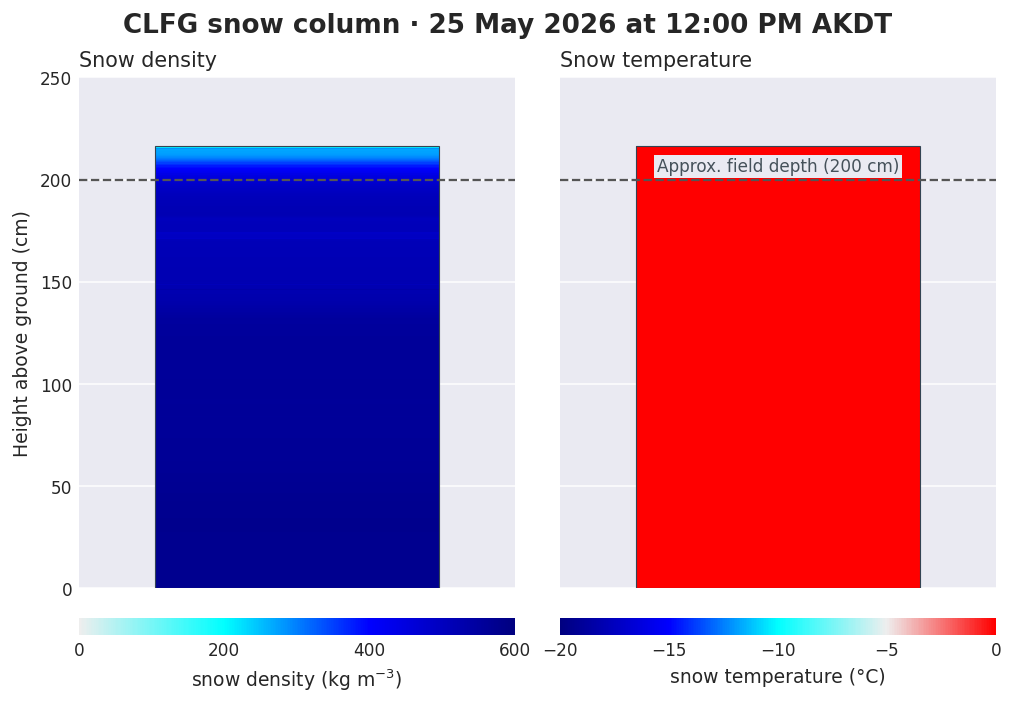

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 5.1), sharey=True, layout="constrained")
fig.suptitle(f"CLFG snow column · {snapshot:%-d %b %Y at %I:%M %p %Z}",
             fontsize=14, weight="bold")
layer_top_cm = tops * 100
layer_bottom_cm = np.r_[0, layer_top_cm[:-1]]
field_depth_cm = observed_depth * 100
depth_max = np.ceil(max(layer_top_cm[-1], field_depth_cm) / 50) * 50
for ax, title, values, cmap, norm, ticks, label in zip(
    axes, ("Snow density", "Snow temperature"), (density, temperature),
    (density_cmap, temperature_cmap), (density_norm, temperature_norm),
    (density_ticks, temperature_ticks), (density_label, temperature_label),
):
    bands = layer_bands(ax, -0.30, 0.30, layer_bottom_cm, layer_top_cm, values, cmap, norm)
    ax.add_patch(Rectangle((-0.30, 0), 0.60, layer_top_cm[-1], fill=False,
                           edgecolor="#344453", linewidth=0.6, zorder=3))
    ax.axhline(field_depth_cm, color="#555555", linestyle="--", linewidth=1.2, zorder=4)
    ax.set(xlim=(-0.46, 0.46), ylim=(0, depth_max), xticks=[])
    ax.set_title(title, loc="left", fontsize=11)
    ax.yaxis.set_major_locator(MultipleLocator(50))
    ax.tick_params(axis="y", labelsize=9)
    fig.colorbar(bands, ax=ax, orientation="horizontal", ticks=ticks, label=label,
                 pad=0.03, aspect=25).ax.tick_params(labelsize=9)

axes[0].set_ylabel("Height above ground (cm)")
axes[1].text(0.5, field_depth_cm + 4, f"Approx. field depth ({field_depth_cm:g} cm)",
             transform=axes[1].get_yaxis_transform(), ha="center", fontsize=9, color="#45515a",
             bbox=dict(facecolor=axes[1].get_facecolor(), edgecolor="none", pad=1.5), zorder=5)
plt.show()
